<a href="https://colab.research.google.com/github/v-yunusic/REPO-PYTHON-VY/blob/main/transacciones-surtidor-2022/bencinera_2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CONTEXTO

El conjunto pertenece a datos registrados por nodos IoT durante los mes de enero a marzo 2022.

Se trata de una serie temporal y contiene en general la siguiente información:

  * Nro de la transacción.
  * Fecha y hora de inicio y de fin de la transacción.
  * Cantidad de litros de combustible despachado.
  * Volumen real registrado por otros nodos IoT en los tanques durante el inicio y fin de la descarga.
  * Estación, surtidor, empresa de origen.
  * Tipo de combustible transaccionado.
  * Geolocalización (si es soportada).
  * Unidad de consumo de destino.
  * Sector de la industria a la que pertenece la estación.

Desde la serie más atómica a la agrupación más general, el orden es el siguiente:
id_bomba --> id_equipo --> id_empresa --> id_industria

# PIP

In [ ]:
pip install matplotlib

In [ ]:
pip install kagglehub

In [1]:
pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 33.1 MB/s  0:00:00


# LIBRERIAS

In [2]:
try:
  import numpy as np
  import matplotlib.pyplot as plt
  import pandas as pd
  import seaborn as sns
  import re # RegEx
  import matplotlib.pyplot as plt
  from sklearn.preprocessing import StandardScaler
  from sklearn.cluster import KMeans
  import gc

  #========= KAGGLE =========#
  import kagglehub

  #======= Rapidfuzz ========#
  from rapidfuzz.distance import Levenshtein

  print('Librerias importadas!')
except Exception as e:
  print(f'Librerias no importadas:\n{e}')

Librerias importadas!


# PREPROCESAMIENTO

In [3]:
# PETICION DE DATA HACIA KAGGLE

path = kagglehub.dataset_download("danielabosch/fuel-transactions-from-gas-pump")
print('DATASET DE KAGGLE CARGADO!')
print(path)

100%|██████████| 21.3M/21.3M [00:00<00:00, 156MB/s]

Extracting files...


DATASET DE KAGGLE CARGADO!
/root/.cache/kagglehub/datasets/danielabosch/fuel-transactions-from-gas-pump/versions/4


In [4]:
data_path = path+'/transacciones_surtidor.csv'

In [5]:
df = pd.read_csv(data_path, sep=',')
df.head()

/tmp/ipykernel_2437/1672446801.py:1: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path, sep=',')


,unique_id_transa,id_transaccion,id_vehiculo,id_usuario,id_equipo,veh_site_id,pump_site_id,tank_site_id,user_site_id,producto,...,temp_final,volumen_comp_15_inicial,volumen_comp_15_final,cantidad_comp_15,codigo_producto,geo_latitud,geo_longitud,id_empresa,id_industria,industria
0,377220101009999,9999,90952,12708,377,000001,1,1,0000,0.0,...,NaN,NaN,NaN,0.000,NaN,NaN,NaN,238,1.0,Transportation
1,504220101006768,6768,101866,6683,504,000001,1,1,0000,0.0,...,NaN,NaN,NaN,158.416,Product 1,NaN,NaN,25,5.0,Distributor
2,534220101007334,7334,123844,34280,534,009593,1,1,3532,0.0,...,30.2,17836.50,17728.5,107.850,0000,NaN,NaN,273,1.0,Transportation
3,878220101002206,2206,141769,46520,878,000103,2,1,0000,0.0,...,NaN,6921.42,NaN,80.002,GOM G3,NaN,NaN,1142,2.0,Mining
4,898220101005224,5224,129356,29688,898,999014,2,1,0001,0.0,...,NaN,NaN,NaN,734.900,Diesel 500,NaN,NaN,1083,1.0,Transportation


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 561747 entries, 0 to 561746
Data columns (total 32 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   unique_id_transa         561747 non-null  int64  
 1   id_transaccion           561747 non-null  int64  
 2   id_vehiculo              561747 non-null  int64  
 3   id_usuario               561747 non-null  int64  
 4   id_equipo                561747 non-null  int64  
 5   veh_site_id              561740 non-null  object 
 6   pump_site_id             561747 non-null  int64  
 7   tank_site_id             561747 non-null  int64  
 8   user_site_id             545281 non-null  object 
 9   producto                 561644 non-null  float64
 10  id_bomba                 561747 non-null  int64  
 11  id_tanque                561747 non-null  int64  
 12  departamento             561747 non-null  object 
 13  cantidad                 561747 non-null  float64
 14  codi

In [6]:
print(f'Cantidad de filas:\n{df.shape[0]}')
print(f'Cantidad de columnas:\n{df.shape[1]}')

Cantidad de filas:
561747
Cantidad de columnas:
32


In [7]:
# DEFINICION DE COLUMNAS NUMERICAS Y CATEGORICAS
col_categoricas = df.select_dtypes(include=['object']).columns.tolist()
col_numericas = df.select_dtypes(exclude=['object','bool']).columns.tolist()
col_bools = df.select_dtypes(include=['bool']).columns.tolist()

In [25]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "pct": df.isna().mean() * 100,
}).sort_values("pct", ascending=False)

nulos

,nulos,pct
unique_id_transa,0,0.0
cantidad,0,0.0
cantidad_comp_15,0,0.0
codigo_error,0,0.0
timestamp,0,0.0
timestamp_stop,0,0.0
nombre_prod,0,0.0
id_industria,0,0.0
industria,0,0.0


In [9]:
df.columns

Index(['unique_id_transa', 'id_transaccion', 'id_vehiculo', 'id_usuario',
       'id_equipo', 'veh_site_id', 'pump_site_id', 'tank_site_id',
       'user_site_id', 'producto', 'id_bomba', 'id_tanque', 'departamento',
       'cantidad', 'codigo_error', 'timestamp', 'timestamp_stop',
       'nombre_prod', 'veh_efficiency', 'volumen_inicial', 'volumen_final',
       'temp_inicial', 'temp_final', 'volumen_comp_15_inicial',
       'volumen_comp_15_final', 'cantidad_comp_15', 'codigo_producto',
       'geo_latitud', 'geo_longitud', 'id_empresa', 'id_industria',
       'industria'],
      dtype='object')

In [18]:
df = df[[
    'unique_id_transa',
    'cantidad',
    'cantidad_comp_15',
    'codigo_error',
    'timestamp',
    'timestamp_stop',
    'nombre_prod',
    'id_industria',
    'industria'
]]

In [19]:
df.head(2)

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,id_industria,industria
0,377220101009999,0.000,0.000,UE,2022-01-01 03:49:21,2022-01-01 03:49:21,Producto 0,1.0,Transportation
1,504220101006768,158.416,158.416,C4,2022-01-01 00:00:36,2022-01-01 00:02:57,Product 1,5.0,Distributor


In [20]:
df.loc[df.duplicated()].shape[0]

0

In [21]:
df['industria'] = df['industria'].fillna('Unknown')
df['nombre_prod'] = df['nombre_prod'].fillna('Unknown')

In [22]:
df[['id_industria','industria']].loc[(df['id_industria'] == 0) & (df['industria']!='Unknown')].shape[0]

0

In [23]:
df['id_industria'] = df['id_industria'].fillna(0)
df['id_industria'].unique()

array([ 1.,  5.,  2.,  4.,  6.,  3.,  0.,  9.,  7.,  8., 10.])

In [24]:
df['industria'].unique()

array(['Transportation', 'Distributor', 'Mining', 'Agriculture',
       'Service Station', 'Oil&Gas', 'Unknown', 'Industry',
       'Construction', 'Public', 'Telcos'], dtype=object)

In [26]:
df.loc[pd.to_datetime(df['timestamp'], errors='coerce').isna()].shape[0], df.loc[pd.to_datetime(df['timestamp_stop'], errors='coerce').isna()].shape[0]

(0, 0)

In [27]:
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
df['timestamp_stop'] = pd.to_datetime(df['timestamp_stop'], errors='coerce')

In [28]:
df.head(2)

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,id_industria,industria
0,377220101009999,0.000,0.000,UE,2022-01-01 03:49:21,2022-01-01 03:49:21,Producto 0,1.0,Transportation
1,504220101006768,158.416,158.416,C4,2022-01-01 00:00:36,2022-01-01 00:02:57,Product 1,5.0,Distributor


# CLASIFICACION POR TIPO COMBUSTIBLE

In [29]:
df.loc[df['nombre_prod'].isna()].shape[0]

0

In [30]:
len(df['nombre_prod'].unique())

102

In [31]:
df['nombre_prod'].unique()

array(['Producto 0', 'Product 1', 'Diesel 500', 'Gasoil GOM G3',
       'Ultra Diesel', 'VP Nafta', 'Super', 'Gasoil GOM G3 Diesel',
       'Infinia Diesel', 'Nafta Super', 'V-Power Nafta', 'Evolux Diesel',
       'V-Power Diesel', 'Diesel', 'Product 3', 'Gasoil', 'VP Diesel',
       'Diesel Grado 2', 'GASOIL', 'Gas Oil Grado 2', 'Gas Oil',
       'Gasoil Grado 3', 'EURO', 'COMUN', 'GOM', 'GASOIL 2', 'Product 2',
       'Producto 1', 'GAS-OIL - GRADO 3', 'nafta', 'DIESEL', 'VP-Diesel',
       'Formula', 'Urea', 'Infinia', 'Producto 2', 'GAS OIL ',
       'Gasoil GOM', 'INFINIA DIESEL', 'GAS OIL', 'Gasoil Comun',
       'Euro Diesel', 'DIESEL-500', 'Ultra Diesel ', 'DIESEL 1',
       'COMBUSTIBLE -  DIESEL 500', 'Gasoil Infinia', 'Diesel Premium',
       'Diesel Comun ', 'Axion Diesel', 'ULTRADIESEL', 'EURODIESEL',
       'Euro-Diesel', 'Ultra-Diesel', 'Nafta', 'Gasoil 500',
       'Diesel 500 PPM', 'S1002050010', 'Puerto Seco La Puerta SA',
       'Cereales Norte SA', 'Gas Oil Comun Gr

In [32]:
df['nombre_prod'] = df['nombre_prod'].str.rstrip().str.lstrip().str.upper()
df['nombre_prod'] = df['nombre_prod'].replace(r'[^a-zA-Z0-9áéíóúÁÉÍÓÚñÑ\s]', '', regex=True)

In [33]:
df['tipo_producto'] = None
df.head(2)

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,id_industria,industria,tipo_producto
0,377220101009999,0.000,0.000,UE,2022-01-01 03:49:21,2022-01-01 03:49:21,PRODUCTO 0,1.0,Transportation,None
1,504220101006768,158.416,158.416,C4,2022-01-01 00:00:36,2022-01-01 00:02:57,PRODUCT 1,5.0,Distributor,None


In [34]:
tipo_diesel = ['infinia','diesel','diésel','euro',
               'combustible','gasoil','gas oil','gom',
               'gas-oil','ultra','formula', 'ud']

tipo_nafta = ['nafta','super']

tipo_urea = ['urea','azul']

# Join une cada valor de las listas con el operando '|' (or)
df.loc[df['nombre_prod'].str.contains('|'.join(tipo_diesel), case=False), 'tipo_producto'] = 'Diesel'
df.loc[df['nombre_prod'].str.contains('|'.join(tipo_nafta), case=False), 'tipo_producto'] = 'Nafta'
df.loc[df['nombre_prod'].str.contains('|'.join(tipo_urea), case=False), 'tipo_producto'] = 'Urea'
df['tipo_producto'] = df['tipo_producto'].fillna('Otro')

In [35]:
df.head(3)

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,id_industria,industria,tipo_producto
0,377220101009999,0.000,0.000,UE,2022-01-01 03:49:21,2022-01-01 03:49:21,PRODUCTO 0,1.0,Transportation,Otro
1,504220101006768,158.416,158.416,C4,2022-01-01 00:00:36,2022-01-01 00:02:57,PRODUCT 1,5.0,Distributor,Otro
2,534220101007334,109.515,107.850,C1,2022-01-01 02:21:27,2022-01-01 02:23:55,DIESEL 500,1.0,Transportation,Diesel


In [36]:
df['nombre_prod'].unique().shape[0]

80

In [39]:
similares = pd.DataFrame(columns=['Producto','Similar','Similitud'])

similares['Producto'] = [p for p in df['nombre_prod'].unique() if p]
lista_similar = []
lista_scores = []

for p in similares['Producto']:
  if isinstance(p, str):
    producto = p

    result = [(Levenshtein.normalized_similarity(producto, str(p_similar)), str(p_similar))
              for p_similar in similares['Producto']
              if (Levenshtein.normalized_similarity(producto, str(p_similar)) != 1)]

    score, similar = max(result, key=lambda x : x[0])

    lista_scores.append(score)
    lista_similar.append(similar)

similares['Similar'] = lista_similar
similares['Similitud'] = lista_scores

In [40]:
dict(zip(similares.Producto, similares.Similar))

{'PRODUCTO 0': 'PRODUCTO 1',
 'PRODUCT 1': 'PRODUCTO 1',
 'DIESEL 500': 'DIESEL500',
 'GASOIL GOM G3': 'GASOIL GOM',
 'ULTRA DIESEL': 'ULTRADIESEL',
 'VP NAFTA': 'VPOWER NAFTA',
 'SUPER': 'NAFTA SUPER',
 'GASOIL GOM G3 DIESEL': 'GASOIL GOM G3',
 'INFINIA DIESEL': 'INFINIA DIÉSEL',
 'NAFTA SUPER': 'SUPER',
 'VPOWER NAFTA': 'VP NAFTA',
 'EVOLUX DIESEL': 'VPOWER DIESEL',
 'VPOWER DIESEL': 'VP DIESEL',
 'DIESEL': 'VPDIESEL',
 'PRODUCT 3': 'PRODUCT 1',
 'GASOIL': 'GAS OIL',
 'VP DIESEL': 'VPDIESEL',
 'DIESEL GRADO 2': 'DIESEL GRADO 3',
 'GAS OIL GRADO 2': 'GASOIL GRADO 2',
 'GAS OIL': 'GASOIL',
 'GASOIL GRADO 3': 'GASOIL  GRADO 3',
 'EURO': 'EURO G3',
 'COMUN': 'FORMULA',
 'GOM': 'COMUN',
 'GASOIL 2': 'GASOIL 1',
 'PRODUCT 2': 'PRODUCTO 2',
 'PRODUCTO 1': 'PRODUCTO 0',
 'GASOIL  GRADO 3': 'GASOIL GRADO 3',
 'NAFTA': 'VP NAFTA',
 'VPDIESEL': 'VP DIESEL',
 'FORMULA': 'FORMULA DIESEL',
 'UREA': 'SUPER',
 'INFINIA': 'INFINIA T40',
 'PRODUCTO 2': 'PRODUCTO 0',
 'GASOIL GOM': 'GASOIL G3',
 'GASOI

In [171]:
#ARREGLO MANUAL A PARTIR DE SIMILARES
dict_similares = {'PRODUCTO 2  DIESEL' : 'PRODUCTO 2 DIESEL',
 'PRODUCT 1': 'PRODUCTO 1',
 'VP NAFTA': 'VPOWER NAFTA',
 'SUPER': 'NAFTA SUPER',
 'GASOIL GOM G3 DIESEL': 'GASOIL GOM G3',
 'VP DIESEL': 'VPOWER DIESEL',
 'VPDIESEL': 'VPOWER DIESEL',
 'GAS OIL GRADO 2': 'GASOIL GRADO 2',
 'GAS OIL': 'GASOIL',
 'GASOIL 1': 'GASOIL',
 'GASOIL COMUN': 'GASOIL',
 'GASOIL GOM': 'GOM',
 'GASOIL  GRADO 3': 'GASOIL GRADO 3',
 'PRODUCT 2': 'PRODUCTO 2',
 'FORMULA': 'FORMULA DIESEL',
 'EURO DIESEL': 'EURODIESEL',
 'DIESEL500': 'DIESEL 500',
 'COMBUSTIBLE  DIESEL 500': 'DIESEL 500',
 'DIESEL COMUN': 'DIESEL',
 'ULTRADIESEL': 'ULTRA DIESEL',
 'GAS OIL 500': 'GASOIL 500',
 'INFINIA DIÉSEL': 'INFINIA DIESEL',
 'INFINIA': 'INFINIA DIESEL',
 'PRODUCTO 1  EURO DIESEL': 'PRODUCTO 1 EURO DIESEL',
 'D 500': 'DIESEL 500',
 'GASOIL MARÍTIMO': 'GOM',
 'EURO': 'EURODIESEL',
 'DIESEL EURO': 'EURODIESEL',
 'UD': 'ULTRA DIESEL'}

In [170]:
df.loc[df['nombre_prod'] == 'COMBUSTIBLE  DIESEL 500']

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,tipo_producto,id_industria,industria,duracion_carga_seg,dia_de_semana


In [42]:
combustibles = pd.DataFrame(columns=['Producto'])
combustibles['Producto'] = [p for p in df['nombre_prod'].unique() if p]
combustibles

,Producto
0,PRODUCTO 0
1,PRODUCT 1
2,DIESEL 500
3,GASOIL GOM G3
4,ULTRA DIESEL
...,...
75,GOM DIESEL 500
76,DIESEL 500 G2
77,COMBUSTIBLE
78,QUANTIUM DIESEL


In [43]:
combustibles['Producto'] = combustibles.replace({'Producto' : dict_similares})

In [44]:
combustibles['Producto'].unique()

array(['PRODUCTO 0', 'PRODUCTO 1', 'DIESEL 500', 'GASOIL GOM G3',
       'ULTRA DIESEL', 'VPOWER NAFTA', 'NAFTA SUPER', 'INFINIA DIESEL',
       'EVOLUX DIESEL', 'VPOWER DIESEL', 'DIESEL', 'PRODUCT 3', 'GASOIL',
       'DIESEL GRADO 2', 'GASOIL GRADO 2', 'GASOIL GRADO 3', 'EURODIESEL',
       'COMUN', 'GOM', 'GASOIL 2', 'PRODUCTO 2', 'NAFTA',
       'FORMULA DIESEL', 'UREA', 'INFINIA', 'GASOIL COMUN', 'DIESEL 1',
       'COMBUSTIBLE   DIESEL 500', 'GASOIL INFINIA', 'DIESEL PREMIUM',
       'DIESEL COMUN', 'AXION DIESEL', 'GASOIL 500', 'DIESEL 500 PPM',
       'S1002050010', 'PUERTO SECO LA PUERTA SA', 'CEREALES NORTE SA',
       'GAS OIL COMUN GR 2', 'GAS OIL EURO GR 3', 'DIESEL GRADO 3',
       'PRODUCTO 1 EURO DIESEL', 'EURO DIESEL GRADO3', 'GASOIL G3',
       'GASOIL 1', 'INFINIA T40', 'GLIFOSATO', 'AZUL 32', 'B100',
       'BIODIESEL', 'INFINIA T20', 'UD', 'UNKNOWN', 'GOM  DIESEL 500',
       'DIESEL 500 G2', 'COMBUSTIBLE', 'QUANTIUM DIESEL', 'EURO G3'],
      dtype=object)

In [166]:
df['nombre_prod'] = df['nombre_prod'].map(dict_similares).fillna(df['nombre_prod'])

In [158]:
df['nombre_prod'].unique().shape[0]

54

In [47]:
df.columns

Index(['unique_id_transa', 'cantidad', 'cantidad_comp_15', 'codigo_error',
       'timestamp', 'timestamp_stop', 'nombre_prod', 'id_industria',
       'industria', 'tipo_producto'],
      dtype='object')

In [49]:
df = df[['unique_id_transa', 'cantidad',
       'cantidad_comp_15', 'codigo_error', 'timestamp', 'timestamp_stop',
       'nombre_prod', 'tipo_producto', 'id_industria', 'industria']]

In [50]:
df.head()

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,tipo_producto,id_industria,industria
0,377220101009999,0.000,0.000,UE,2022-01-01 03:49:21,2022-01-01 03:49:21,PRODUCTO 0,Otro,1.0,Transportation
1,504220101006768,158.416,158.416,C4,2022-01-01 00:00:36,2022-01-01 00:02:57,PRODUCTO 1,Otro,5.0,Distributor
2,534220101007334,109.515,107.850,C1,2022-01-01 02:21:27,2022-01-01 02:23:55,DIESEL 500,Diesel,1.0,Transportation
3,878220101002206,80.002,80.002,C0,2022-01-01 02:42:11,2022-01-01 02:42:11,GASOIL GOM G3,Diesel,2.0,Mining
4,898220101005224,734.900,734.900,BF,2022-01-01 00:15:56,2022-01-01 00:27:25,DIESEL 500,Diesel,1.0,Transportation


In [53]:
df['codigo_error'] = df['codigo_error'].str.upper()
df['codigo_error'].unique()

array(['UE', 'C4', 'C1', 'C0', 'BF', 'ES', 'C2', 'BE', 'BD', 'UL', 'BA',
       'RS', 'H2', 'H1', 'H4', 'RC', 'H5', 'ER', 'H3', 'E1', 'UD', 'PR',
       'B0', 'U3', '00', 'BR', 'EE', 'U4'], dtype=object)

In [54]:
df['duracion_carga_seg'] = (df['timestamp_stop'] - df['timestamp']).dt.total_seconds()

#Lunes=0, Domingo=6
df['dia_de_semana'] = df['timestamp'].dt.dayofweek

In [60]:
df['dia_de_semana'].unique()

array([5, 6, 0, 1, 2, 3, 4], dtype=int32)

In [64]:
df.loc[df['dia_de_semana'] == 0, 'dia_de_semana'] = 'Lunes'
df.loc[df['dia_de_semana'] == 1, 'dia_de_semana'] = 'Martes'
df.loc[df['dia_de_semana'] == 2, 'dia_de_semana'] = 'Miercoles'
df.loc[df['dia_de_semana'] == 3, 'dia_de_semana'] = 'Jueves'
df.loc[df['dia_de_semana'] == 4, 'dia_de_semana'] = 'Viernes'
df.loc[df['dia_de_semana'] == 5, 'dia_de_semana'] = 'Sabado'
df.loc[df['dia_de_semana'] == 6, 'dia_de_semana'] = 'Domingo'

/tmp/ipykernel_2437/3745828864.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Lunes' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  df.loc[df['dia_de_semana'] == 0, 'dia_de_semana'] = 'Lunes'


In [65]:
df['dia_de_semana'].unique()

array(['Sabado', 'Domingo', 'Lunes', 'Martes', 'Miercoles', 'Jueves',
       'Viernes'], dtype=object)

In [66]:
df.head()

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,tipo_producto,id_industria,industria,duracion_carga_seg,dia_de_semana
0,377220101009999,0.000,0.000,UE,2022-01-01 03:49:21,2022-01-01 03:49:21,PRODUCTO 0,Otro,1.0,Transportation,0.0,Sabado
1,504220101006768,158.416,158.416,C4,2022-01-01 00:00:36,2022-01-01 00:02:57,PRODUCTO 1,Otro,5.0,Distributor,141.0,Sabado
2,534220101007334,109.515,107.850,C1,2022-01-01 02:21:27,2022-01-01 02:23:55,DIESEL 500,Diesel,1.0,Transportation,148.0,Sabado
3,878220101002206,80.002,80.002,C0,2022-01-01 02:42:11,2022-01-01 02:42:11,GASOIL GOM G3,Diesel,2.0,Mining,0.0,Sabado
4,898220101005224,734.900,734.900,BF,2022-01-01 00:15:56,2022-01-01 00:27:25,DIESEL 500,Diesel,1.0,Transportation,689.0,Sabado


In [55]:
df['duracion_carga_seg'].head(3)

,duracion_carga_seg
0,0.0
1,141.0
2,148.0


In [56]:
df.loc[df['duracion_carga_seg'] > 30*60]

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,tipo_producto,id_industria,industria,duracion_carga_seg,dia_de_semana
686,569220101009816,990.002,991.19,BF,2022-01-01 15:23:11,2022-01-01 16:23:50,GASOIL,Diesel,2.0,Mining,3639.0,5
749,898220101005228,2500.000,2500.00,C0,2022-01-01 14:54:04,2022-01-01 15:49:34,DIESEL 500,Diesel,1.0,Transportation,3330.0,5
1315,851220101000836,2819.480,2790.44,BF,2022-01-01 22:30:00,2022-01-01 23:02:33,DIESEL 500,Diesel,1.0,Transportation,1953.0,5
1316,851220102000837,3039.430,3007.82,BF,2022-01-02 00:46:51,2022-01-02 01:21:56,DIESEL 500,Diesel,1.0,Transportation,2105.0,6
1328,898220101005232,2500.000,2500.00,C0,2022-01-01 22:24:32,2022-01-01 22:57:56,DIESEL 500,Diesel,1.0,Transportation,2004.0,5
...,...,...,...,...,...,...,...,...,...,...,...,...
561321,1118220410000223,8206.550,8236.92,BF,2022-04-10 08:22:35,2022-04-10 12:39:17,GOM DIESEL 500,Diesel,0.0,Unknown,15402.0,6
561337,1118220412000239,6997.020,7036.90,BF,2022-04-12 08:29:38,2022-04-12 12:21:29,GOM DIESEL 500,Diesel,0.0,Unknown,13911.0,1
561348,1121220404000005,0.000,0.00,BD,2022-04-04 21:39:59,2022-04-05 05:58:05,PRODUCTO 0,Otro,5.0,Distributor,29886.0,0
561377,1146220410000388,3430.000,3408.05,C1,2022-04-10 00:01:17,2022-04-10 00:53:31,PRODUCTO 0,Otro,4.0,Agriculture,3134.0,6


In [57]:
round(df['duracion_carga_seg'].describe())

,duracion_carga_seg
count,561747.0
mean,256.0
std,4553.0
min,0.0
25%,0.0
50%,92.0
75%,182.0
max,1225117.0


In [59]:
df.head(3)

,unique_id_transa,cantidad,cantidad_comp_15,codigo_error,timestamp,timestamp_stop,nombre_prod,tipo_producto,id_industria,industria,duracion_carga_seg,dia_de_semana
0,377220101009999,0.000,0.000,UE,2022-01-01 03:49:21,2022-01-01 03:49:21,PRODUCTO 0,Otro,1.0,Transportation,0.0,5
1,504220101006768,158.416,158.416,C4,2022-01-01 00:00:36,2022-01-01 00:02:57,PRODUCTO 1,Otro,5.0,Distributor,141.0,5
2,534220101007334,109.515,107.850,C1,2022-01-01 02:21:27,2022-01-01 02:23:55,DIESEL 500,Diesel,1.0,Transportation,148.0,5


# OUTLIERS

### CANTIDAD COMBUSTIBLE

In [58]:
df[['cantidad','cantidad_comp_15']].describe()

,cantidad,cantidad_comp_15
count,561747.000000,561747.000000
mean,249.660747,248.124236
std,1700.396255,1684.471268
min,-29616.000000,-29257.600000
25%,23.488500,23.240700
50%,60.888000,60.424000
75%,143.505500,142.917000
max,100000.000000,99610.000000


In [69]:
round(df['duracion_carga_seg'].describe())

,duracion_carga_seg
count,561747.0
mean,256.0
std,4553.0
min,0.0
25%,0.0
50%,92.0
75%,182.0
max,1225117.0


##### VALORES NEGATIVOS

In [111]:
df.loc[df['cantidad'] < 0].shape[0] == df.loc[df['cantidad_comp_15'] < 0].shape[0]

True

In [112]:
df[['codigo_error','cantidad_comp_15']].loc[df['cantidad_comp_15'] < 0]

,codigo_error,cantidad_comp_15
5619,RS,-5426.87000
23123,RS,-8805.60000
34709,RS,-9806.08000
34717,RS,-5566.07000
59265,RS,-48.39800
74734,RS,-8186.97000
98187,RS,-8822.54000
113110,RS,-6472.44000
138848,RS,-5888.14000
177740,RS,-21478.30000


In [116]:
df = df.loc[(df['cantidad_comp_15'] >= 0) & (df['cantidad'] >= 0)]

In [129]:
percentil_99 = np.percentile(df['cantidad_comp_15'], 99)
percentil_95 = np.percentile(df['cantidad_comp_15'], 95)
percentil_95, percentil_99

(np.float64(514.4718999999988), np.float64(2500.01))

In [131]:
df['cantidad_comp_15'].loc[(df['cantidad_comp_15'] <= percentil_99)].describe()

,cantidad_comp_15
count,556098.000000
mean,126.030009
std,209.438594
min,0.000000
25%,22.800250
50%,60.035000
75%,137.910500
max,2500.010000


In [139]:
#IA
prom_industrias = df.groupby('industria')['cantidad_comp_15'].mean().reset_index()
prom_industrias.columns = ['industria', 'promedio (litros)']
prom_industrias = prom_industrias.sort_values('promedio (litros)', ascending=False)
prom_industrias

,industria,promedio
5,Oil&Gas,1513.015822
4,Mining,979.441946
10,Unknown,305.089181
0,Agriculture,212.360546
1,Construction,204.205532
9,Transportation,168.384398
6,Public,124.393606
3,Industry,122.352317
7,Service Station,106.712946
2,Distributor,92.702386


In [172]:
prom_producto = df.groupby('nombre_prod')['cantidad_comp_15'].mean().reset_index()
prom_producto.columns = ['Producto','Promedio (litros)']
prom_producto = prom_producto.sort_values('Promedio (litros)', ascending=False)
prom_producto

,Producto,Promedio (litros)
32,GOM,6064.426431
45,QUANTIUM DIESEL,3975.485246
3,BIODIESEL,1396.861667
8,DIESEL,978.150400
47,ULTRA DIESEL,493.914881
48,UNKNOWN,334.157699
24,GASOIL 2,309.846433
27,GASOIL GOM G3,303.800300
6,COMBUSTIBLE DIESEL 500,269.492162
44,PUERTO SECO LA PUERTA SA,261.411071


<Axes: xlabel='Promedio (litros)', ylabel='Producto'>

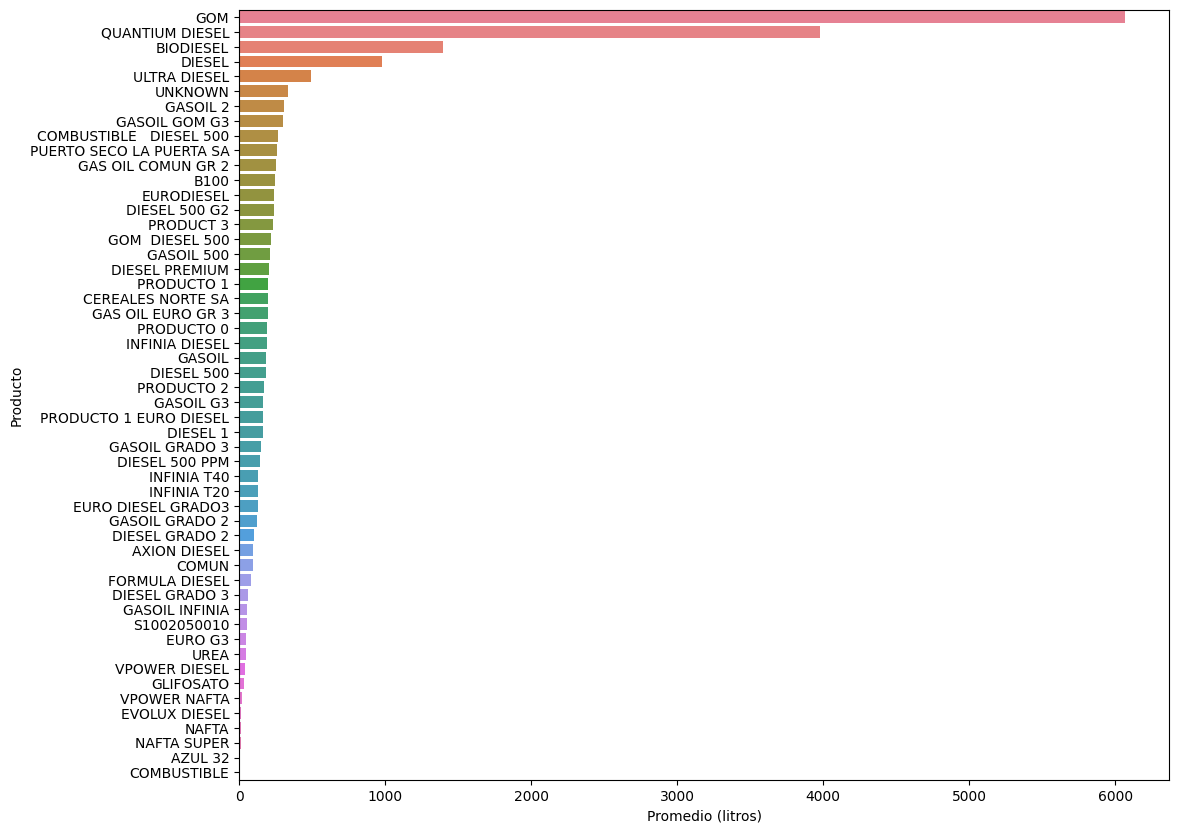

In [173]:
fig, ax = plt.subplots(figsize=(12, 10))
sns.barplot(prom_producto, y="Producto", x="Promedio (litros)", hue='Producto', ax=ax)

# CODIGO VIEJO

In [ ]:
productos = [p.rstrip().lstrip().upper() for p in df['nombre_prod'].unique() if p]
productos = [re.sub(r'[^a-zA-Z0-9áéíóúÁÉÍÓÚñÑ\s]', '', p) for p in productos if p]

productos = list(set(productos))

combustibles = pd.DataFrame(columns=['Producto','Tipo'])
combustibles['Producto'] = productos
combustibles.head(3)

,Producto,Tipo
0,EURO DIESEL,NaN
1,AZUL 32,NaN
2,COMBUSTIBLE DIESEL 500,NaN


In [ ]:
combustibles.shape[0]

80

In [ ]:
# TIPOS DE PRODUCTO:

tipo_diesel = ['infinia','diesel','diésel','euro',
               'combustible','gasoil','gas oil','gom',
               'gas-oil','ultra','formula', 'ud']

tipo_nafta = ['nafta','super']

tipo_urea = ['urea','azul']

for p in combustibles['Producto']:
  if isinstance(p, str):
    producto = p.lower()

    if any(t in producto for t in tipo_diesel):
      combustibles.loc[combustibles['Producto'].str.lower() == producto, 'Tipo'] = 'Diesel'

    if any(t in producto for t in tipo_nafta):
      combustibles.loc[combustibles['Producto'].str.lower() == producto, 'Tipo'] = 'Nafta'

    if any(t in producto for t in tipo_urea):
      combustibles.loc[combustibles['Producto'].str.lower() == producto, 'Tipo'] = 'Urea'

    combustibles['Tipo'] = combustibles['Tipo'].fillna('Otro')



In [ ]:
combustibles.loc[combustibles['Tipo'] == 'Diesel']

,Producto,Tipo
0,EURO DIESEL,Diesel
2,COMBUSTIBLE DIESEL 500,Diesel
3,GAS OIL COMUN GR 2,Diesel
5,DIESEL PREMIUM,Diesel
6,GASOIL,Diesel
8,GASOIL GOM,Diesel
9,BIODIESEL,Diesel
10,VPDIESEL,Diesel
11,DIESEL 500 G2,Diesel
12,INFINIA T20,Diesel


In [ ]:
combustibles['Tipo'].unique()

array(['Diesel', 'Urea', 'Otro', 'Nafta'], dtype=object)